## Import Necessary Libraries

In [210]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## Data Understanding and Data Proprocessing

In [211]:
df = pd.read_csv ("../Midterm_Project/water_potability.csv")
df.columns = df.columns.str.strip()
df.head(10)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562,0


In [212]:
print(df.shape)
print(df.columns)
print(df.info())

(3276, 10)
Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB
None


In [213]:
df['Potability'].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

In [214]:
print(df.duplicated().sum())

0


In [215]:
df.dtypes

ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object

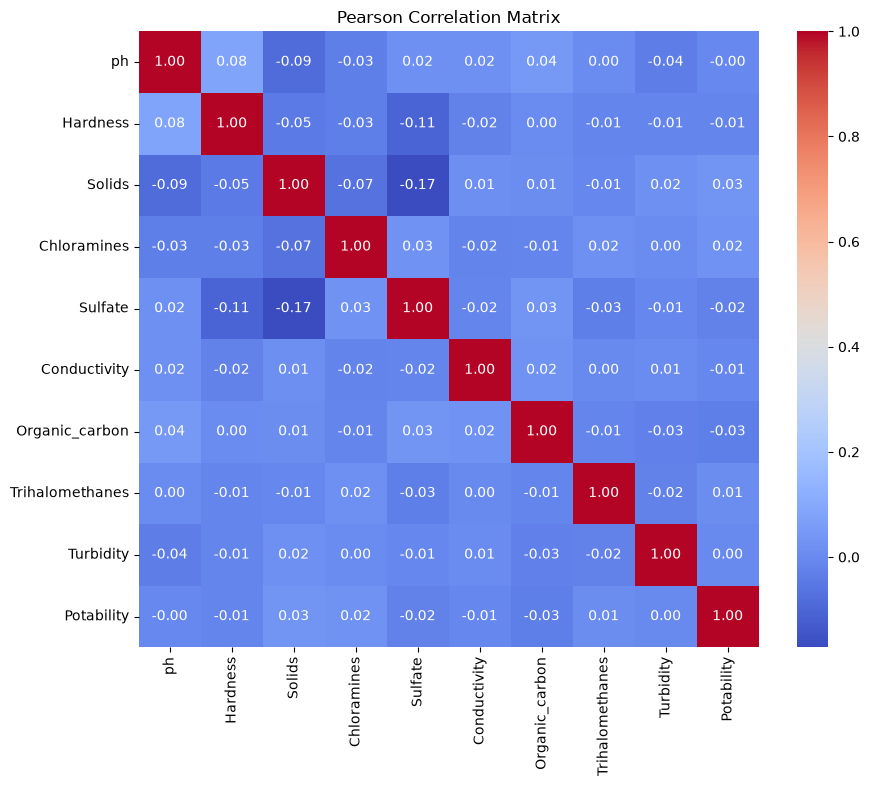

In [216]:
#Pearson : Measures linear relationships.
#Spearman : Measures monotonic relationships using ranks.
#Kendall : Measures rank-based association.
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(method="pearson", numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Pearson Correlation Matrix")
plt.show()

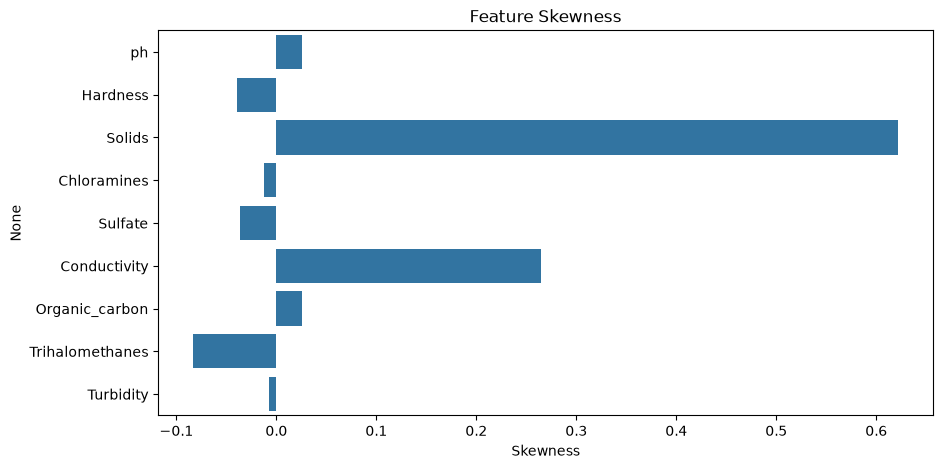

In [217]:
Columns = df.drop(columns=["Potability"]).select_dtypes(include="number").columns

skewness = df[Columns].skew()

plt.figure(figsize=(10, 5))
sns.barplot(x=skewness.values, y=skewness.index)
plt.title("Feature Skewness")
plt.xlabel("Skewness")
plt.show()

In [218]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [219]:
print(df[['ph', 'Sulfate', 'Trihalomethanes']].describe())

                ph      Sulfate  Trihalomethanes
count  2785.000000  2495.000000      3114.000000
mean      7.080795   333.775777        66.396293
std       1.594320    41.416840        16.175008
min       0.000000   129.000000         0.738000
25%       6.093092   307.699498        55.844536
50%       7.036752   333.073546        66.622485
75%       8.062066   359.950170        77.337473
max      14.000000   481.030642       124.000000


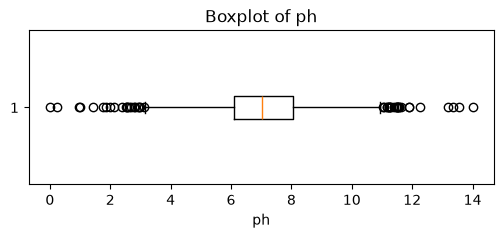

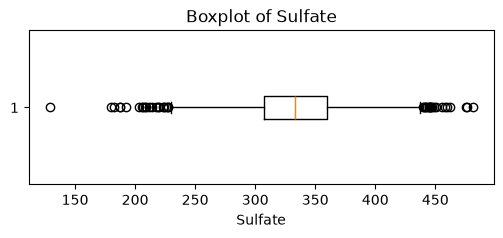

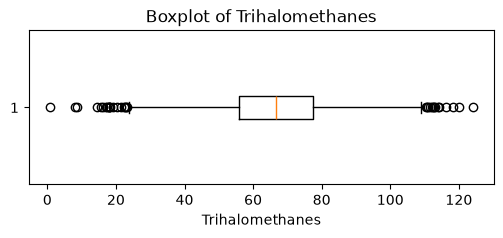

In [220]:
columns = ['ph', 'Sulfate', 'Trihalomethanes']

for col in columns:
    plt.figure(figsize=(6, 2))
    plt.boxplot(df[col].dropna(), orientation="horizontal")
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

In [221]:
for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    percentage = len(outliers) / df[col].notna().sum() * 100

    print(f"{col}: {len(outliers)} outliers ({percentage:.2f}%)")

ph: 46 outliers (1.65%)
Sulfate: 41 outliers (1.64%)
Trihalomethanes: 33 outliers (1.06%)


## Spliting Data into target and features

In [222]:
X = df.drop('Potability', axis=1)
y = df['Potability']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3276, 9)
y shape: (3276,)


In [223]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
) # stratify=y keeps nearly the same proportion of both water classes in training and testing.

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2620, 9)
X_test: (656, 9)
y_train: (2620,)
y_test: (656,)


## Filling Missing Value and Scaling

In [224]:
mean_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

median_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Scale before KNN imputation so larger-unit features do not dominate distances.
KNN_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5))
])

preprocessing_methods = {
    "Median": median_pipeline,
    "KNN": KNN_pipeline,
    "Mean": mean_pipeline
}

In [225]:
# Confirm that preprocessing method leaves NaN values.
# For an initial check, fit on training data only. CV will refit preprocessing inside every fold.
for name, prep in preprocessing_methods.items():
    X_check = prep.fit_transform(X_train)
    print(f"{name} missing values:", np.isnan(X_check).sum())

Median missing values: 0
KNN missing values: 0
Mean missing values: 0


## Model Training

In [226]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(class_weight="balanced")
}

metrics = ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]

Mean Imputation + 3 models

In [227]:
mean_results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessing', mean_pipeline),
        ('model', model)
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metrics)
    mean_results.append({
        'Imputation': 'Mean',
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean()
    })

mean_df = pd.DataFrame(mean_results)
display(mean_df.round(4))

,Imputation,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Mean,Logistic Regression,0.4962,0.4906,0.3801,0.4648,0.4178
1,Mean,KNN,0.6347,0.5930,0.5432,0.4031,0.4627
2,Mean,SVM,0.6672,0.6499,0.5735,0.5714,0.5715


Median Imputation + 3 models

In [228]:
median_results = []

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessing", median_pipeline),
        ("model", model)
    ])

    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metrics) #
    median_results.append({
        "Imputation": "Median",
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(), # Measures the overall percentage of correct water classifications.
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(), # Measures performance across potable and non-potable classes without letting the larger class dominate.
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean()
    })

median_df = pd.DataFrame(median_results)
display(median_df.round(2))

,Imputation,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Median,Logistic Regression,0.49,0.49,0.38,0.46,0.42
1,Median,KNN,0.64,0.59,0.54,0.40,0.46
2,Median,SVM,0.67,0.65,0.57,0.57,0.57


KNN Imputation + 3 models

In [229]:
knn_results = []

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessing", KNN_pipeline),
        ("model", model)
    ])

    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metrics)
    knn_results.append({
        "Imputation": "KNN",
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean()
    })

knn_df = pd.DataFrame(knn_results)
display(knn_df.round(2))

,Imputation,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,KNN,Logistic Regression,0.49,0.48,0.37,0.45,0.41
1,KNN,KNN,0.62,0.58,0.52,0.39,0.45
2,KNN,SVM,0.66,0.64,0.57,0.57,0.57


In [230]:
comparison_df = pd.concat([median_df, knn_df , mean_df], ignore_index=True)
comparison_df = comparison_df.sort_values("F1 Score", ascending=False)
display(comparison_df.round(4))

,Imputation,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
8,Mean,SVM,0.6672,0.6499,0.5735,0.5714,0.5715
2,Median,SVM,0.6668,0.6492,0.5733,0.5694,0.5704
5,KNN,SVM,0.6611,0.6444,0.5657,0.5685,0.5661
1,Median,KNN,0.6351,0.5935,0.5436,0.4041,0.4635
7,Mean,KNN,0.6347,0.5930,0.5432,0.4031,0.4627
4,KNN,KNN,0.6244,0.5829,0.5240,0.3943,0.4496
6,Mean,Logistic Regression,0.4962,0.4906,0.3801,0.4648,0.4178
0,Median,Logistic Regression,0.4947,0.4888,0.3783,0.4619,0.4155
3,KNN,Logistic Regression,0.4897,0.4829,0.3725,0.4521,0.4081


Selecting best model based on CV F1

In [231]:
best = comparison_df.iloc[0]
print("Best Model:", best["Model"])
print("Best Imputation:", best["Imputation"])
print("5-Fold CV F1:", round(best["F1 Score"], 4))

Best Model: SVM
Best Imputation: Mean
5-Fold CV F1: 0.5715


In [232]:
best_model = Pipeline([
    ("preprocessing", mean_pipeline),
    ("model", SVC(class_weight="balanced"))
])

best_model.fit(X_train, y_train)

print("Best model trained successfully!")

Best model trained successfully!


In [233]:
param_grid = {
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

grid_search = GridSearchCV(
    estimator=best_model,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1 #Use all available CPU cores to run tasks in parallel.
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

# Replace the original model with the tuned pipeline
best_model = grid_search.best_estimator_

Best Parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV F1 Score: 0.5715436438492738


Accuracy: 0.622
Balanced Accuracy: 0.6014
Precision: 0.5159
Recall: 0.5078
F1 Score: 0.5118
ROC-AUC: 0.6445
              precision    recall  f1-score   support

           0       0.69      0.69      0.69       400
           1       0.52      0.51      0.51       256

    accuracy                           0.62       656
   macro avg       0.60      0.60      0.60       656
weighted avg       0.62      0.62      0.62       656



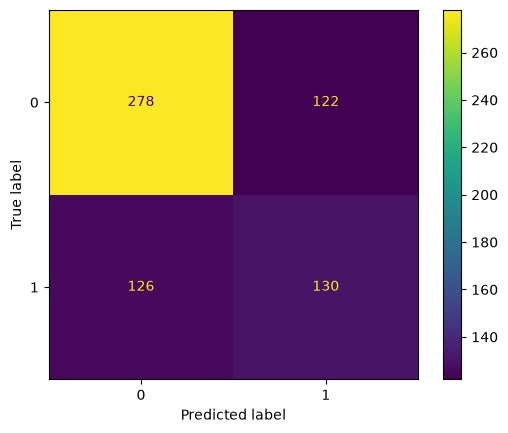

Unsafe predicted as safe: 122
False-safe rate: 0.305


In [234]:
y_pred = best_model.predict(X_test)

# Evaluate model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

# ROC-AUC for SVM
y_score = best_model.decision_function(X_test)
print("ROC-AUC:", round(roc_auc_score(y_test, y_score), 4))

# Classification report
print(classification_report(y_test, y_pred))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

# False-safe predictions
cm = confusion_matrix(y_test, y_pred)
print("Unsafe predicted as safe:", cm[0, 1])
print("False-safe rate:", round(cm[0, 1] / cm[0].sum(), 4))

Checking whether my trained model performs better than a basic prediction strategy.

In [235]:
dummy = DummyClassifier(strategy="most_frequent") #It always predicts the most common class in the training dataset.In my dataset, the DummyClassifier will always predict 0 because it is the majority class.
dummy.fit(X_train, y_train)
print("Baseline Test Accuracy:", round(dummy.score(X_test, y_test), 4))
print("Best Model Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Baseline Test Accuracy: 0.6098
Best Model Test Accuracy: 0.622


Saving model

In [236]:
import pickle
with open("water_potability_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Model saved successfully!")

Model saved successfully!


Loading Model

In [237]:
with open("water_potability_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

print("Model loaded successfully!")

Model loaded successfully!


Testing with Sample

In [238]:
samples = X_test.iloc[:10]

predictions = loaded_model.predict(samples)

results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": predictions
})

results["Correct"] = results["Actual"] == results["Predicted"]

display(results)

,Actual,Predicted,Correct
0,1,0,False
1,0,0,True
2,0,0,True
3,0,0,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,1,0,False
9,1,0,False


In [239]:
print(type(loaded_model))
print(loaded_model)

<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('imputer', SimpleImputer()),
                                 ('scaler', StandardScaler())])),
                ('model', SVC(C=1, class_weight='balanced'))])
